# UK Railways Network Analysis 

Because I had to change dataset in between assignment 1 and assignment 2, here is a summary of the new dataset information and code from the first assignment tasks, to explore the statistical aspects of the network.

The new network maps the rail connections between train stations in the UK (data available at https://github.com/andresantoro/Tranet_data/tree/master to be downloaded, originally scraped from http://www.opentraintimes.com/). Dataset was provided as multiple .txt files. Thus, the first steps of this notebook combine the different files and export them as a .csv. 

Nodes represent train stations, while edges represent whether there is a direct connection between the two stations. The graph is undirected, and simply indicates whether there is a service between two nodes (i.e. stations), and unweighted.

**N.B.:**

For the purposes of Assignment 2, only download the dataset "uk_train_network.csv" available at https://github.com/marcocusi/model-based-decisions/tree/main/Assignment%202/data , place it in a folder called data, and run the code in the Notebook from the section Assignment 2.

The raw-data consolidation step runs only if the original datasets on carrier, station and layer are also present (download from https://github.com/andresantoro/Tranet_data/tree/master and include them in data folder). 

Results are saved to data/ and figures to figures/ only when the corresponding directory already exists; the notebook does not create output directories.

# Summary of Assignment 1 (\& Data Processing)

## 1. Imports

In [195]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import random
import re
from collections import Counter
from pathlib import Path

%matplotlib inline
plt.style.use("default")

## 2. Raw Data Loading and Cleaning (Optional, from .txt)

In [196]:
DATA_DIR = Path("data")
SAVE_DIR = Path("figures")
DATA_FILE = DATA_DIR / "uk_train_network.csv"


def save_dataframe_if_directory_exists(dataframe, filename, directory=DATA_DIR):
    """Save a DataFrame only when its destination directory already exists."""
    if not directory.is_dir():
        print(f"Not saving {filename}: directory '{directory}' does not exist.")
        return None

    output_path = directory / filename
    dataframe.to_csv(output_path, index=False, encoding="utf-8-sig")
    print(f"Saved data to {output_path}")
    return output_path


def save_figure_if_directory_exists(figure, filename, dpi=300):
    """Save a figure in SAVE_DIR only when that directory already exists."""
    if not SAVE_DIR.is_dir():
        print(f"Not saving {filename}: directory '{SAVE_DIR}' does not exist.")
        return None

    output_path = SAVE_DIR / filename
    figure.savefig(output_path, dpi=dpi, bbox_inches="tight")
    print(f"Saved figure to {output_path}")
    return output_path


def consolidate_railway_data(data_dir=DATA_DIR):
    """Combine the original carrier-layer text files into a station-connection CSV.

    The consolidation is optional: it runs only when the data directory, carrier
    and station lists, and at least one layer file are present. Invalid records
    and station names absent from the supplied node list are reported and, when
    possible, saved alongside the consolidated dataset.
    """
    if not data_dir.is_dir():
        print(f"Skipping raw-data consolidation: '{data_dir}' does not exist.")
        return None

    companies_file = data_dir / "rail_companies.txt"
    nodes_file = data_dir / "nodes_list.txt"
    if not companies_file.is_file() or not nodes_file.is_file():
        print("Skipping raw-data consolidation: carrier or station list is missing.")
        return None

    layer_files = []
    for file_path in data_dir.iterdir():
        match = re.fullmatch(r"layer(\d+)\.txt(?:_original)?", file_path.name)
        if match:
            layer_files.append((int(match.group(1)), file_path))
    layer_files.sort(key=lambda item: item[0])

    if not layer_files:
        print("Skipping raw-data consolidation: no layer files were found.")
        return None

    companies = {}
    with companies_file.open("r", encoding="utf-8-sig") as file:
        for line in file:
            line = line.strip()
            if line:
                code, name = line.split("|", 1)
                companies[len(companies) + 1] = {
                    "code": code.strip(),
                    "name": name.strip(),
                }

    with nodes_file.open("r", encoding="utf-8-sig") as file:
        known_nodes = {line.strip() for line in file if line.strip()}

    connections = []
    invalid_rows = []
    unknown_nodes = set()

    for layer_number, file_path in layer_files:
        if layer_number not in companies:
            print(f"Skipping layer {layer_number}: no carrier mapping was found.")
            continue

        carrier = companies[layer_number]
        with file_path.open("r", encoding="utf-8-sig") as file:
            for line_number, line in enumerate(file, start=1):
                line = line.strip()
                if not line:
                    continue

                endpoints = line.split("|")
                if len(endpoints) != 2:
                    invalid_rows.append({
                        "file": file_path.name,
                        "line": line_number,
                        "content": line,
                    })
                    continue

                source, target = (endpoint.strip() for endpoint in endpoints)
                if source not in known_nodes:
                    unknown_nodes.add(source)
                if target not in known_nodes:
                    unknown_nodes.add(target)

                connections.append({
                    "source": source,
                    "target": target,
                    "carrier_code": carrier["code"],
                    "carrier_name": carrier["name"],
                    "layer": layer_number,
                })

    columns = ["source", "target", "carrier_code", "carrier_name", "layer"]
    consolidated = pd.DataFrame(connections, columns=columns)
    save_dataframe_if_directory_exists(
        consolidated, "uk_train_network.csv", directory=data_dir
    )

    print(f"Connection records: {len(consolidated):,}")
    print(f"Unique stations: {len(set(consolidated['source']) | set(consolidated['target'])):,}")
    print(f"Carriers represented: {consolidated['carrier_code'].nunique():,}")
    print(f"Invalid rows: {len(invalid_rows):,}")
    print(f"Station names absent from nodes_list.txt: {len(unknown_nodes):,}")

    if invalid_rows:
        save_dataframe_if_directory_exists(
            pd.DataFrame(invalid_rows), "invalid_rows.csv", directory=data_dir
        )
    if unknown_nodes:
        unknown_frame = pd.DataFrame(sorted(unknown_nodes), columns=["unknown_station"])
        save_dataframe_if_directory_exists(
            unknown_frame, "unknown_stations.csv", directory=data_dir
        )

    return consolidated


consolidated_data = consolidate_railway_data()


Saved data to data/uk_train_network.csv
Connection records: 8,996
Unique stations: 2,941
Carriers represented: 41
Invalid rows: 0
Station names absent from nodes_list.txt: 0


## 3. Loading the new dataset

In [197]:
if not DATA_FILE.is_file():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_FILE}. Place uk_train_network.csv in a data/ "
        "directory alongside the notebook, or provide the original carrier, station "
        "and layer files there to generate it."
    )

df = pd.read_csv(DATA_FILE)
required_columns = {"source", "target", "carrier_code", "carrier_name", "layer"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"CSV is missing required columns: {sorted(missing_columns)}")

print(f"Loaded {len(df):,} connection records")
print(f"Data shape: {df.shape}")

# Remove records without valid station endpoints or carrier identifiers.
df = df.dropna(subset=["source", "target", "carrier_code"]).copy()

# Normalize whitespace and remove empty station names.
for column in ["source", "target", "carrier_code", "carrier_name"]:
    df[column] = df[column].astype("string").str.strip()
df = df[(df["source"] != "") & (df["target"] != "")].copy()

print(f"Records after cleaning: {len(df):,}")
display(df.head())


Loaded 8,996 connection records
Data shape: (8996, 5)
Records after cleaning: 8,996


,source,target,carrier_code,carrier_name,layer
0,Southampton Central,Eastleigh T.&R.S.M.D,AR,Alliance Rail,1
1,Birmingham International,Chester,AW,Arriva Trains Wales,2
2,Chester,Wolverhampton,AW,Arriva Trains Wales,2
3,Cardiff Central Bus Station,Cardiff International APT,AW,Arriva Trains Wales,2
4,Cardiff Central,Canton C.S.D.,AW,Arriva Trains Wales,2


## 4. Constructing the network

In [198]:
def create_railway_network(data):
    """Build an undirected graph by aggregating carrier records for each station pair.

    Each edge stores the number of distinct carriers serving the pair as its
    weight, together with the carrier identifiers and names.
    """
    graph = nx.Graph()
    edge_data = {}

    for row in data.itertuples(index=False):
        source = str(row.source).strip()
        target = str(row.target).strip()
        if not source or not target or source == target:
            continue

        # Canonical ordering prevents duplicate undirected station pairs.
        u, v = sorted((source, target))
        key = (u, v)
        if key not in edge_data:
            edge_data[key] = {"carriers": set(), "carrier_names": set()}

        edge_data[key]["carriers"].add(str(row.carrier_code))
        if pd.notna(row.carrier_name):
            edge_data[key]["carrier_names"].add(str(row.carrier_name))

    for (u, v), info in edge_data.items():
        graph.add_edge(
            u,
            v,
            weight=len(info["carriers"]),
            carriers=sorted(info["carriers"]),
            carrier_names=sorted(info["carrier_names"]),
        )

    print(
        f"Network created with {graph.number_of_nodes():,} stations "
        f"and {graph.number_of_edges():,} unique station-pair connections."
    )
    return graph


G = create_railway_network(df)


Network created with 2,941 stations and 8,572 unique station-pair connections.


## 5. Statistical Analysis

In [199]:
def network_summary(G, data):
    """Print topology and degree statistics for the aggregate railway graph.

    Shortest-path statistics are computed on the largest connected component,
    because they are not defined across disconnected components.
    """
    if G.number_of_nodes() == 0:
        raise ValueError("The graph is empty. Check the input CSV.")

    N = G.number_of_nodes()
    M = G.number_of_edges()
    components = list(nx.connected_components(G))
    largest_cc = max(components, key=len)
    G_lcc = G.subgraph(largest_cc).copy()

    degrees = [degree for _, degree in G.degree()]
    strengths = [strength for _, strength in G.degree(weight="weight")]

    print("=" * 65)
    print("UK RAILWAY NETWORK SUMMARY")
    print("=" * 65)
    print(f"Connection records in CSV: {len(data):,}")
    print(f"Stations (nodes): {N:,}")
    print(f"Unique station-pair connections (edges): {M:,}")
    print(f"Carriers represented: {data['carrier_code'].nunique():,}")
    print(f"Connected components: {len(components):,}")
    print(f"Largest connected component: {G_lcc.number_of_nodes():,} stations")
    print(f"LCC proportion: {G_lcc.number_of_nodes() / N * 100:.2f}%")
    print(f"Network density: {nx.density(G):.8f}")
    print(f"Average degree: {np.mean(degrees):.4f}")
    print(f"Average weighted degree (carrier strength): {np.mean(strengths):.4f}")
    print(f"Average clustering: {nx.average_clustering(G):.4f}")
    print(f"Global transitivity: {nx.transitivity(G):.4f}")

    assortativity = nx.degree_assortativity_coefficient(G)
    print(f"Degree assortativity: {assortativity:.4f}")

    # Path statistics are calculated on the largest connected component,
    # as in the previous assignment.
    if G_lcc.number_of_nodes() > 1:
        print(
            "Average shortest path length (LCC): "
            f"{nx.average_shortest_path_length(G_lcc):.4f}"
        )
        print(f"Network diameter (LCC): {nx.diameter(G_lcc):,}")
    else:
        print("Path length and diameter: not defined for a one-node LCC")

    print("\nDegree statistics:")
    print(f"Mean degree: {np.mean(degrees):.2f}")
    print(f"Median degree: {np.median(degrees):.2f}")
    print(f"Maximum degree: {max(degrees):,}")
    print(f"Minimum degree: {min(degrees):,}")
    print(f"Standard deviation: {np.std(degrees):.2f}")

    print("\nTop 10 stations by degree:")
    for station, degree in sorted(G.degree(), key=lambda x: x[1], reverse=True)[:10]:
        print(f"{station}: {degree}")

    print("\nTop 10 station pairs by number of carriers:")
    top_edges = sorted(
        G.edges(data=True),
        key=lambda x: x[2]["weight"],
        reverse=True
    )[:10]
    for u, v, attrs in top_edges:
        print(f"{u} — {v}: {attrs['weight']} carrier(s)")


network_summary(G, df)

UK RAILWAY NETWORK SUMMARY
Connection records in CSV: 8,996
Stations (nodes): 2,941
Unique station-pair connections (edges): 8,572
Carriers represented: 41
Connected components: 34
Largest connected component: 2,867 stations
LCC proportion: 97.48%
Network density: 0.00198276
Average degree: 5.8293
Average weighted degree (carrier strength): 6.1176
Average clustering: 0.2564
Global transitivity: 0.1724
Degree assortativity: -0.0271
Average shortest path length (LCC): 4.6761
Network diameter (LCC): 13

Degree statistics:
Mean degree: 5.83
Median degree: 3.00
Maximum degree: 89
Minimum degree: 1
Standard deviation: 9.15

Top 10 stations by degree:
Edinburgh: 89
Manchester Piccadilly: 84
Cardiff Central: 80
London Waterloo (Main): 78
Eastleigh East Yard: 75
Birmingham New Street: 74
Leeds: 74
London Victoria: 71
Hoo Junction Up Yard: 71
Glasgow Central High Level: 65

Top 10 station pairs by number of carriers:
Craigentinny T.& R.S.M.D — Edinburgh: 7 carrier(s)
Edinburgh — Dundee: 5 carrie

## 6. Degree Distributions

Saved figure to figures/uk_rail_degree_distribution.png


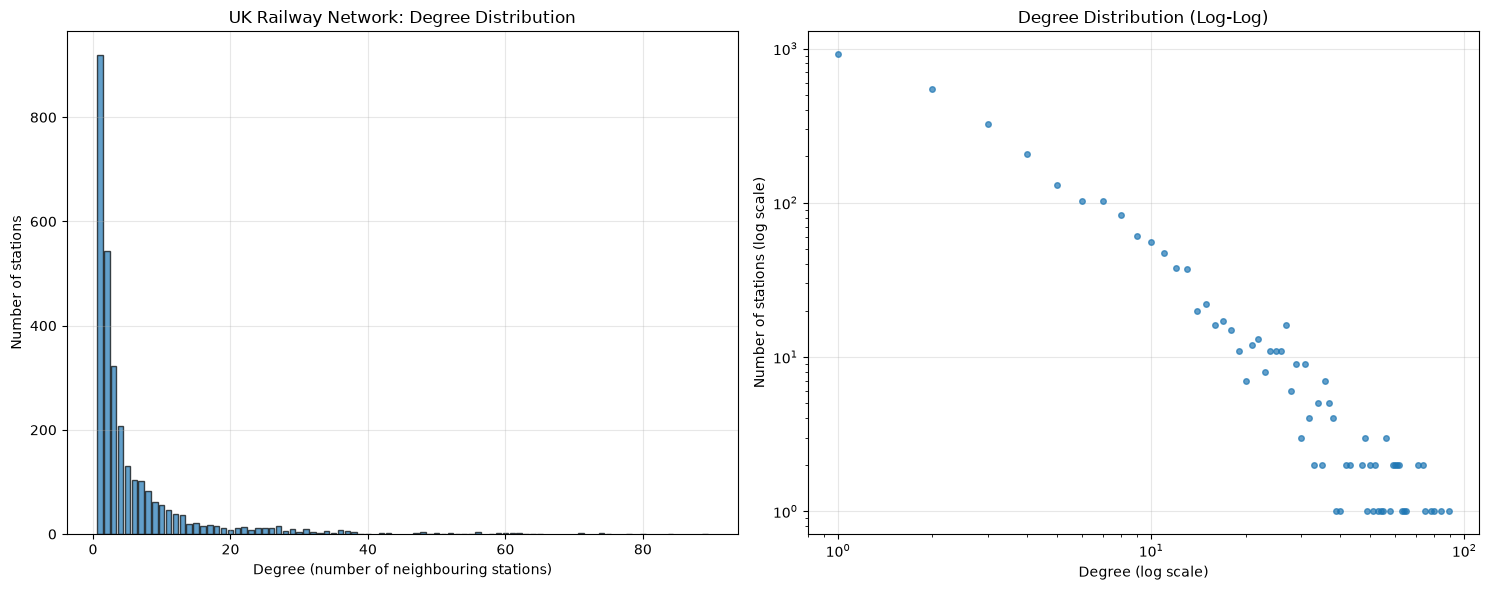


Degree distribution statistics:
Mean degree: 5.83
Median degree: 3.00
Maximum degree: 89
Minimum degree: 1
Standard deviation: 9.15


In [200]:
def plot_degree_distribution(G):
    """Plot degree distribution on linear and log-log scales."""
    degrees = [degree for _, degree in G.degree()]
    degree_counts = Counter(degrees)

    degree_values = sorted(degree_counts)
    counts = [degree_counts[d] for d in degree_values]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

    ax1.bar(degree_values, counts, alpha=0.7, edgecolor="black")
    ax1.set_xlabel("Degree (number of neighbouring stations)")
    ax1.set_ylabel("Number of stations")
    ax1.set_title("UK Railway Network: Degree Distribution")
    ax1.grid(True, alpha=0.3)

    # Degree zero does not occur in a graph built only from observed edges;
    # filter non-positive values for logarithmic axes regardless.
    positive = [(d, c) for d, c in zip(degree_values, counts) if d > 0 and c > 0]
    if positive:
        x, y = zip(*positive)
        ax2.loglog(x, y, "o", alpha=0.7, markersize=4)
    ax2.set_xlabel("Degree (log scale)")
    ax2.set_ylabel("Number of stations (log scale)")
    ax2.set_title("Degree Distribution (Log-Log)")
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    save_figure_if_directory_exists(plt.gcf(), "uk_rail_degree_distribution.png")
    plt.show()

    print("\nDegree distribution statistics:")
    print(f"Mean degree: {np.mean(degrees):.2f}")
    print(f"Median degree: {np.median(degrees):.2f}")
    print(f"Maximum degree: {max(degrees):,}")
    print(f"Minimum degree: {min(degrees):,}")
    print(f"Standard deviation: {np.std(degrees):.2f}")


plot_degree_distribution(G)

## 7. Centrality Analysis

In [201]:
def calculate_centrality_measures(G):
    """Calculate four centrality measures for the railway network.

    Betweenness is approximated with sampled source nodes for large graphs.
    Closeness and eigenvector centrality are calculated on the largest
    connected component; stations outside it receive a score of zero.
    """
    if G.number_of_nodes() == 0:
        raise ValueError("Cannot calculate centrality on an empty graph.")

    centralities = {}

    print("Calculating degree centrality...")
    centralities["degree"] = nx.degree_centrality(G)

    print("Calculating betweenness centrality...")
    if G.number_of_nodes() > 1000:
        k = min(1000, G.number_of_nodes())
        centralities["betweenness"] = nx.betweenness_centrality(
            G, k=k, seed=42
        )
        print(f"Using approximation with k={k} sampled nodes.")
    else:
        centralities["betweenness"] = nx.betweenness_centrality(G)

    largest_cc = max(nx.connected_components(G), key=len)
    G_lcc = G.subgraph(largest_cc).copy()

    print("Calculating closeness centrality on the largest connected component...")
    closeness_lcc = nx.closeness_centrality(G_lcc)
    centralities["closeness"] = {
        node: closeness_lcc.get(node, 0.0) for node in G.nodes()
    }

    print("Calculating eigenvector centrality on the largest connected component...")
    try:
        eigenvector_lcc = nx.eigenvector_centrality(
            G_lcc, max_iter=1000, tol=1e-06
        )
    except nx.PowerIterationFailedConvergence:
        print("Eigenvector centrality did not converge; using NumPy solver.")
        eigenvector_lcc = nx.eigenvector_centrality_numpy(G_lcc)

    centralities["eigenvector"] = {
        node: eigenvector_lcc.get(node, 0.0) for node in G.nodes()
    }

    return centralities


centralities = calculate_centrality_measures(G)

Calculating degree centrality...
Calculating betweenness centrality...
Using approximation with k=1000 sampled nodes.
Calculating closeness centrality on the largest connected component...
Calculating eigenvector centrality on the largest connected component...


In [202]:
def display_top_stations(centralities, top_n=10):
    """Print the highest-ranked stations for each supplied centrality measure."""
    print("=" * 70)
    print(f"TOP {top_n} RAILWAY STATIONS BY CENTRALITY")
    print("=" * 70)

    for measure_name, values in centralities.items():
        print(f"\n{measure_name.upper()} CENTRALITY")
        print("-" * 50)

        ranked = sorted(values.items(), key=lambda item: item[1], reverse=True)
        for rank, (station, score) in enumerate(ranked[:top_n], start=1):
            print(f"{rank:2d}. {station}: {score:.6f}")


display_top_stations(centralities, top_n=10)

TOP 10 RAILWAY STATIONS BY CENTRALITY

DEGREE CENTRALITY
--------------------------------------------------
 1. Edinburgh: 0.030272
 2. Manchester Piccadilly: 0.028571
 3. Cardiff Central: 0.027211
 4. London Waterloo (Main): 0.026531
 5. Eastleigh East Yard: 0.025510
 6. Birmingham New Street: 0.025170
 7. Leeds: 0.025170
 8. London Victoria: 0.024150
 9. Hoo Junction Up Yard: 0.024150
10. Glasgow Central High Level: 0.022109

BETWEENNESS CENTRALITY
--------------------------------------------------
 1. Edinburgh: 0.080691
 2. Wembley Eur Frt Ops Cntre: 0.073670
 3. Derby R.T.C. (Network Rail): 0.060486
 4. Eastleigh East Yard: 0.055816
 5. Basford Hall S.S.M.: 0.050638
 6. Hoo Junction Up Yard: 0.047291
 7. Belmont Down Yard: 0.041955
 8. London Euston: 0.040427
 9. Toton North Yard: 0.039392
10. Reading: 0.038651

CLOSENESS CENTRALITY
--------------------------------------------------
 1. Wembley Eur Frt Ops Cntre: 0.324318
 2. Edinburgh: 0.321553
 3. Derby R.T.C. (Network Rail): 0.

## 8. Visual comparison of centralities

Saved figure to figures/uk_rail_centrality_comparison.png


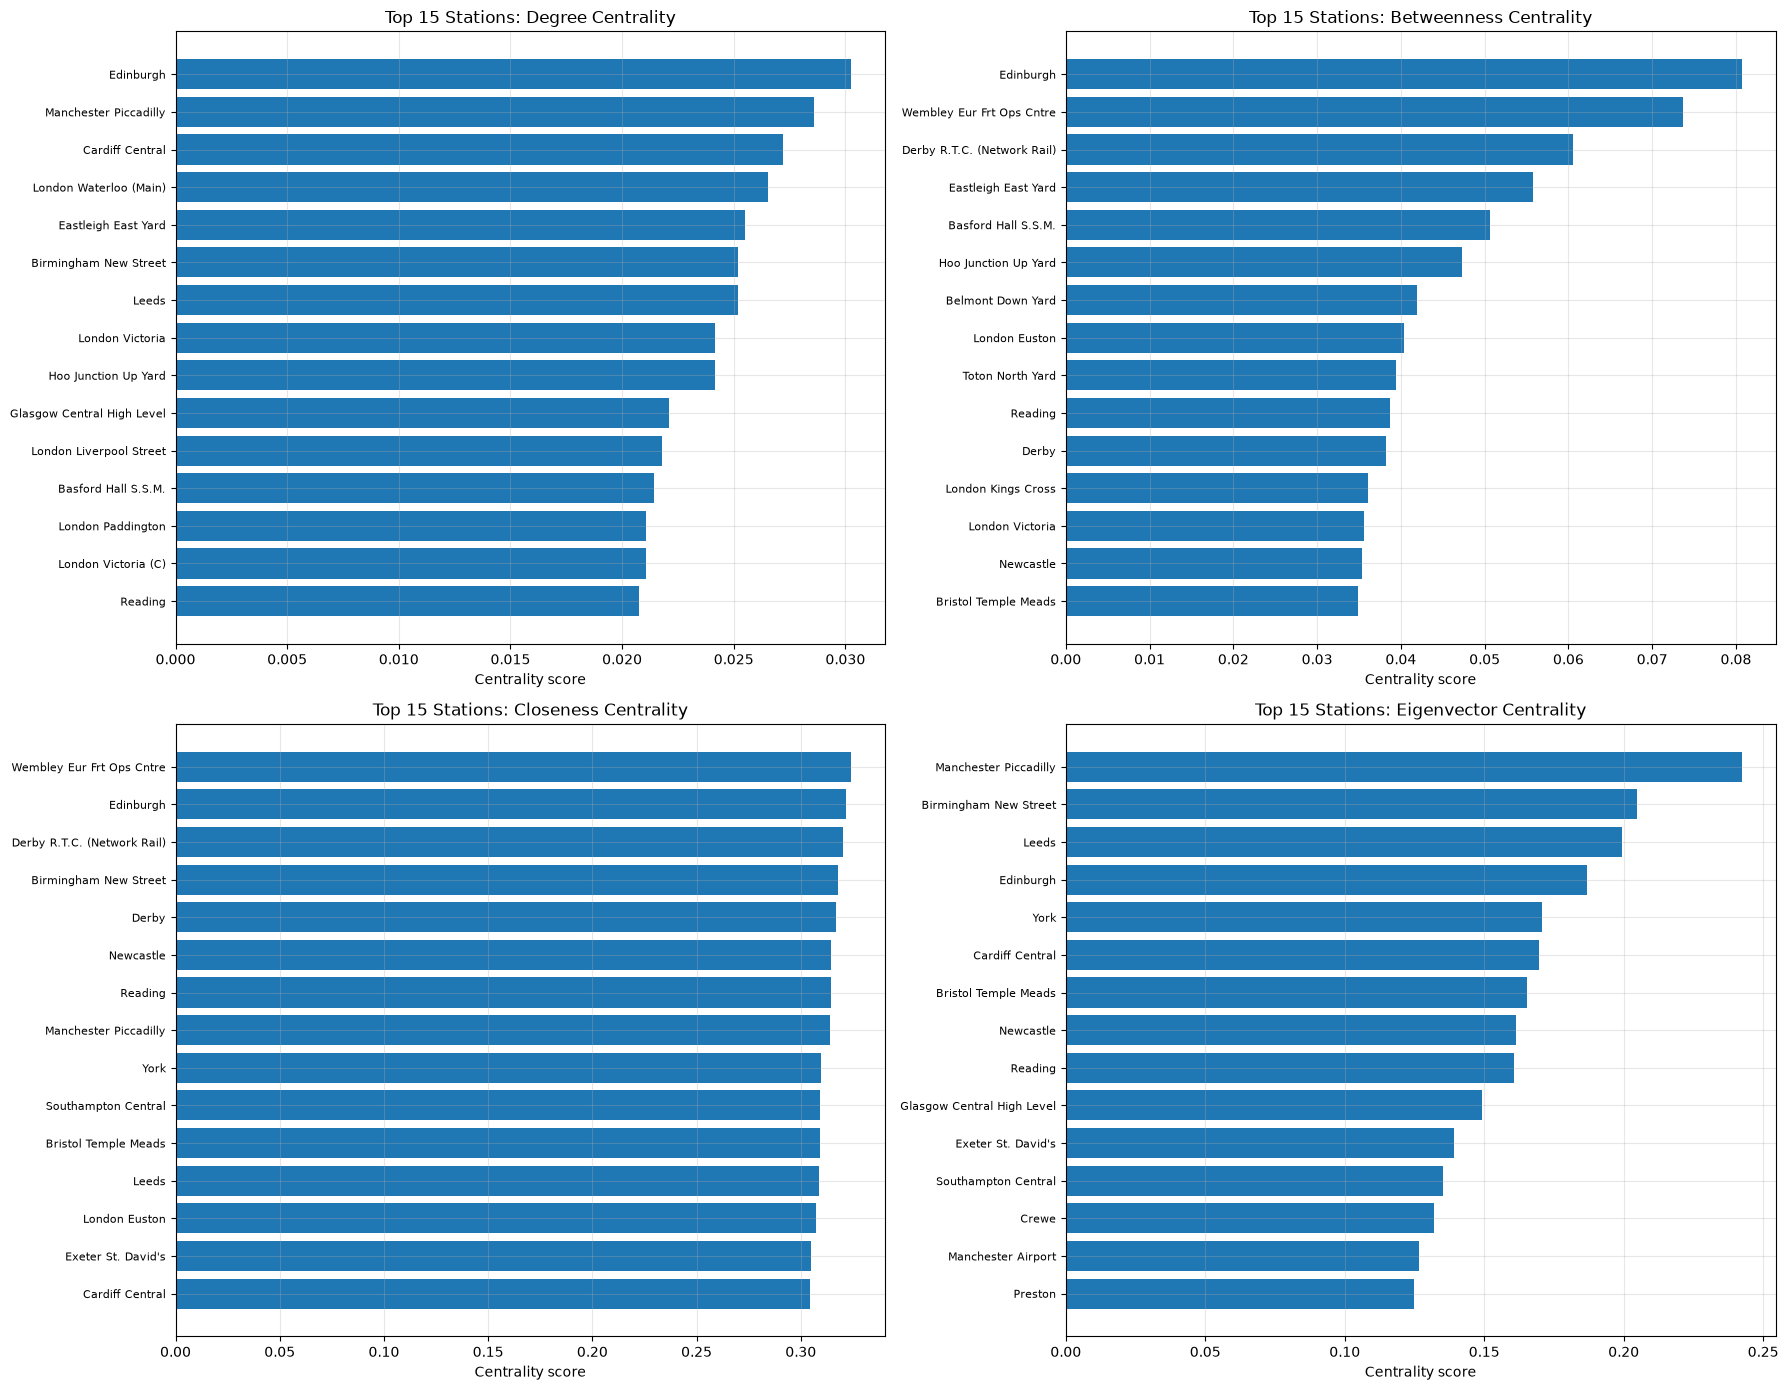

In [203]:
centrality_names = ["degree", "betweenness", "closeness", "eigenvector"]
centrality_titles = [
    "Degree Centrality",
    "Betweenness Centrality",
    "Closeness Centrality",
    "Eigenvector Centrality"
]

fig, axes = plt.subplots(2, 2, figsize=(18, 14))
axes = axes.flatten()

for ax, name, title in zip(axes, centrality_names, centrality_titles):
    top_stations = sorted(
        centralities[name].items(),
        key=lambda item: item[1],
        reverse=True
    )[:15]

    stations = [item[0] for item in top_stations]
    scores = [item[1] for item in top_stations]

    ax.barh(range(len(stations)), scores)
    ax.set_yticks(range(len(stations)))
    ax.set_yticklabels(stations, fontsize=8)
    ax.set_xlabel("Centrality score")
    ax.set_title(f"Top 15 Stations: {title}")
    ax.grid(True, alpha=0.3)
    ax.invert_yaxis()

plt.tight_layout()
save_figure_if_directory_exists(fig, "uk_rail_centrality_comparison.png")
plt.show()

# Assignment 2: Threshold Dynamics and Spreading

## 1. Settings

In [204]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import random

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.grid"] = False
plt.rcParams["figure.dpi"] = 120

print("Packages loaded.")


Packages loaded.


## 2. Experimental Configuration

In [222]:
# Network sizes for the synthetic comparison networks.
N = 1000
k_avg = 6

# Baseline Monte Carlo settings.
SEED_FRACTION = 0.05
ENSEMBLES = 3
RUNS_PER_SETTING = 30

# Heterogeneous threshold settings for the baseline experiment.
THRESHOLD_MODE = "beta"  #corresponding to Beta(2,5)
PHI_MEAN = 2 / 7
PHI_STD = np.sqrt(10 / 392)

MAX_STEPS = 200
RANDOM_SEED = 42

# Homogeneous-threshold sensitivity experiments.
TAU_VALUES = np.round(np.arange(0.05, 0.501, 0.05), 2)
F0_VALUES = [0.01, 0.02, 0.05, 0.10]
INTERMEDIATE_TAU = 0.20

print(
    f"Baseline seed fraction={SEED_FRACTION:.0%}; "
    f"synthetic network ensembles={ENSEMBLES}; "
    f"independent runs per condition={RUNS_PER_SETTING}"
)


Baseline seed fraction=5%; synthetic network ensembles=3; independent runs per condition=30


## 3. Network Generator

The experiment compares three synthetic network models (ER, WS, BA) with the empirical UK Rail network constructed in the first part of this notebook. The empirical graph keeps its observed station-to-station topology; the model treats connections as unweighted, just as the threshold-dynamics function does.

In [223]:
def build_networks(N, k_avg, seed_base=0, empirical_graph=None):
    """Create ER, WS and BA graphs, optionally adding the empirical UK Rail graph.

    The N and k_avg parameters apply only to the synthetic networks. The
    empirical graph is copied without edge weights because adoption depends
    on the unweighted fraction of active neighbours.
    """
    p_er = k_avg / (N - 1)
    G_er = nx.erdos_renyi_graph(N, p_er, seed=seed_base + 1)

    k_ws = max(2, int(round(k_avg)))
    if k_ws % 2 == 1:
        k_ws += 1
    G_ws = nx.watts_strogatz_graph(N, k_ws, 0.1, seed=seed_base + 2)

    m_ba = max(1, int(k_avg // 2))
    G_ba = nx.barabasi_albert_graph(N, m_ba, seed=seed_base + 3)

    networks = {"ER": G_er, "WS": G_ws, "BA": G_ba}
    if empirical_graph is not None:
        rail_graph = nx.Graph()
        rail_graph.add_nodes_from(empirical_graph.nodes())
        rail_graph.add_edges_from(empirical_graph.edges())
        networks["UK Rail"] = rail_graph

    return networks


graphs = build_networks(N, k_avg, seed_base=RANDOM_SEED, empirical_graph=G)
{name: (network.number_of_nodes(), network.number_of_edges())
 for name, network in graphs.items()}


{'ER': (1000, 2974),
 'WS': (1000, 3000),
 'BA': (1000, 2991),
 'UK Rail': (2941, 8572)}

## 4. Threshold Distributions

In [224]:
def draw_thresholds(G, mode="uniform", phi_mean=0.3, phi_std=0.1, rng=None):
    """Draw and return one adoption threshold in [0, 1] for every graph node.

    The mode selects a uniform, beta, constant, or clipped-normal distribution.
    Pass a NumPy Generator to make the draw reproducible.
    """
    rng = np.random.default_rng() if rng is None else rng
    nodes_list = list(G.nodes())

    if mode == "uniform":
        values = rng.uniform(0, 1, len(nodes_list))
    elif mode == "beta":
        # Parameterize Beta(alpha, beta) from the requested mean and standard deviation.
        variance = float(phi_std) ** 2
        max_variance = float(phi_mean) * (1.0 - float(phi_mean))
        if not 0 < phi_mean < 1 or not 0 < variance < max_variance:
            raise ValueError("For beta thresholds, require 0 < phi_mean < 1 and 0 < phi_std² < mean*(1-mean).")
        concentration = max_variance / variance - 1.0
        alpha = float(phi_mean) * concentration
        beta = (1.0 - float(phi_mean)) * concentration
        values = rng.beta(alpha, beta, len(nodes_list))
    elif mode == "constant":
        values = np.full(len(nodes_list), float(phi_mean))
    elif mode == "normal":
        values = np.clip(rng.normal(phi_mean, phi_std, len(nodes_list)), 0, 1)
    else:
        raise ValueError(f"Unknown threshold mode: {mode}")

    return dict(zip(nodes_list, map(float, values)))


# Illustrate the selected baseline threshold distribution.
_preview_rng = np.random.default_rng(RANDOM_SEED)
for name, network in graphs.items():
    th = draw_thresholds(network, mode=THRESHOLD_MODE,
                         phi_mean=PHI_MEAN, phi_std=PHI_STD, rng=_preview_rng)
    values = np.asarray(list(th.values()))
    print(name, "threshold mean:", round(float(values.mean()), 3),
          "threshold SD:", round(float(values.std()), 3))


ER threshold mean: 0.292 threshold SD: 0.157
WS threshold mean: 0.282 threshold SD: 0.15
BA threshold mean: 0.281 threshold SD: 0.162
UK Rail threshold mean: 0.285 threshold SD: 0.16


## 5. Threshold Dynamics

In [225]:
def threshold_dynamics(G, seeds, thresholds, max_steps=100):
    """Simulate progressive fractional-threshold contagion with synchronous updates.

    A node adopts when the fraction of its active neighbours is at least its
    assigned threshold. Newly adopting nodes influence other nodes only in the
    next time step. The function returns the final node states and the adoption
    fraction at every time step, including the initial seed state.
    """
    if G.number_of_nodes() == 0:
        raise ValueError("Threshold dynamics requires a non-empty graph.")

    missing_thresholds = set(G.nodes()) - set(thresholds)
    if missing_thresholds:
        raise ValueError(f"Thresholds are missing for {len(missing_thresholds)} graph nodes.")

    unknown_seeds = set(seeds) - set(G.nodes())
    if unknown_seeds:
        raise ValueError(f"The seed set contains {len(unknown_seeds)} nodes not in the graph.")

    adopted = {node: 0 for node in G.nodes()}
    for seed in seeds:
        adopted[seed] = 1

    history = [sum(adopted.values()) / G.number_of_nodes()]
    for _ in range(max_steps):
        next_state = adopted.copy()
        changed = False

        for node in G.nodes():
            if adopted[node] == 1:
                continue

            neighbours = list(G.neighbors(node))
            if not neighbours:
                continue

            active_fraction = sum(adopted[neighbour] for neighbour in neighbours) / len(neighbours)
            if active_fraction >= thresholds[node]:
                next_state[node] = 1
                changed = True

        adopted = next_state
        history.append(sum(adopted.values()) / G.number_of_nodes())
        if not changed:
            break

    return adopted, np.asarray(history)


## 6. Measurement Utilities

In [226]:
def final_adoption_fraction(adopted):
    """Return the fraction of graph nodes that are active in the final state."""
    if not adopted:
        return np.nan
    return sum(adopted.values()) / len(adopted)


def time_to_fraction(history, target=0.5):
    """Return the first time index at which adoption reaches target, or NaN."""
    reached = np.where(np.asarray(history) >= target)[0]
    return float(reached[0]) if len(reached) else np.nan


## 7. Seeding Strategies — Heuristics

In [227]:
def random_seeds(G, B, rng=None):
    """Select B distinct nodes uniformly at random from the graph."""
    rng = random if rng is None else rng
    return rng.sample(list(G.nodes()), min(B, G.number_of_nodes()))


def high_degree_seeds(G, B):
    """Select the B highest-degree nodes, breaking ties by node identifier."""
    ranked = sorted(G.degree(), key=lambda item: (-item[1], str(item[0])))
    return [node for node, _ in ranked[:B]]


def betweenness_seeds(G, B, betweenness=None):
    """Select the B highest-betweenness nodes, breaking ties by node identifier.

    Betweenness is calculated when it is not supplied; for large graphs the
    calculation uses up to 1,000 sampled source nodes.
    """
    if betweenness is None:
        sample_size = min(1000, G.number_of_nodes()) if G.number_of_nodes() > 1000 else None
        betweenness = nx.betweenness_centrality(
            G, k=sample_size, seed=RANDOM_SEED
        )

    ranked = sorted(
        betweenness.items(),
        key=lambda item: (-item[1], str(item[0]))
    )
    return [node for node, _ in ranked[:B]]


## 8. MonteCarlo Experiment runner

In [228]:
STRATEGIES = ["Random", "Degree", "Betweenness"]
strategy_order = STRATEGIES.copy()
STRATEGY_COLORS = {
    "Random": "#4C78A8",
    "Degree": "#F58518",
    "Betweenness": "#54A24B",
}


def _make_strategy_seeds(G, B, rng, betweenness):
    """Build paired random, degree and betweenness seed sets for one trial."""
    return {
        "Random": random_seeds(G, B, rng),
        "Degree": high_degree_seeds(G, B),
        "Betweenness": betweenness_seeds(G, B, betweenness=betweenness),
    }


def _run_replicates(G, network_name, condition_name, parameter_value,
                    seed_fraction, threshold_mode, tau, phi_mean, phi_std,
                    runs, max_steps, seed_base, ensemble=0):
    """Run paired Monte Carlo trials and return trial-level and trajectory data.

    Within each run, all three strategies share the same threshold assignment.
    Random seeds and threshold draws use deterministic run-specific seeds.
    """
    B = max(1, int(np.ceil(seed_fraction * G.number_of_nodes())))
    sample_size = min(1000, G.number_of_nodes()) if G.number_of_nodes() > 1000 else None
    betweenness = nx.betweenness_centrality(G, k=sample_size, seed=seed_base)
    result_rows, trajectory_rows = [], []

    for run in range(runs):
        run_seed = seed_base + run
        np_rng = np.random.default_rng(run_seed)
        py_rng = random.Random(run_seed)

        if threshold_mode == "constant":
            thresholds = draw_thresholds(
                G, mode="constant", phi_mean=tau, rng=np_rng
            )
        else:
            thresholds = draw_thresholds(
                G, mode=threshold_mode, phi_mean=phi_mean,
                phi_std=phi_std, rng=np_rng
            )

        seed_sets = _make_strategy_seeds(G, B, py_rng, betweenness)
        for strategy, seeds in seed_sets.items():
            adopted, history = threshold_dynamics(
                G, seeds, thresholds, max_steps=max_steps
            )
            final_size = final_adoption_fraction(adopted)
            converged = (
                len(history) < max_steps + 1
                or np.isclose(history[-1], history[-2])
            )
            convergence_time = max(0, len(history) - 2) if converged else max_steps
            time_50 = time_to_fraction(history, target=0.5)

            result_rows.append({
                "Ensemble": ensemble,
                "Run": run,
                "Network": network_name,
                "Experiment": condition_name,
                "Parameter": parameter_value,
                "SeedFraction": seed_fraction,
                "SeedCount": B,
                "ThresholdMode": threshold_mode,
                "Tau": tau if threshold_mode == "constant" else np.nan,
                "Strategy": strategy,
                "FinalAdoption": final_size,
                "CascadeSuccess": int(final_size >= 0.5),
                "ConvergenceTime": convergence_time,
                "Converged": bool(converged),
                "Time50": time_50,
                "Efficiency": final_size / seed_fraction,
            })

            # Pad each trajectory with its steady-state value for aggregation.
            padded_history = np.pad(
                history,
                (0, max_steps + 1 - len(history)),
                mode="constant",
                constant_values=history[-1],
            )
            for time_step, fraction in enumerate(padded_history):
                trajectory_rows.append({
                    "Ensemble": ensemble,
                    "Run": run,
                    "Network": network_name,
                    "Experiment": condition_name,
                    "Parameter": parameter_value,
                    "Strategy": strategy,
                    "Time": time_step,
                    "AdoptionFraction": fraction,
                })

    return result_rows, trajectory_rows


def run_baseline_experiments(N, k_avg, empirical_graph, ensembles=3,
                             runs_per_setting=30, seed_fraction=0.05,
                             threshold_mode="beta", phi_mean=0.3, phi_std=0.1,
                             max_steps=200, seed_base=42):
    """Compare the three seeding strategies across synthetic and UK Rail graphs."""
    all_results, all_trajectories = [], []
    network_names = ["ER", "WS", "BA", "UK Rail"]

    for ensemble in range(ensembles):
        network_set = build_networks(
            N, k_avg, seed_base=seed_base + ensemble * 10,
            empirical_graph=empirical_graph,
        )
        for network_name in network_names:
            current_graph = network_set[network_name]
            rows, trajectories = _run_replicates(
                current_graph,
                network_name,
                "Baseline",
                threshold_mode,
                seed_fraction,
                threshold_mode,
                None,
                phi_mean,
                phi_std,
                runs_per_setting,
                max_steps,
                seed_base + ensemble * 100000
                + (network_names.index(network_name) + 1) * 10000,
                ensemble=ensemble,
            )
            all_results.extend(rows)
            all_trajectories.extend(trajectories)

    return pd.DataFrame(all_results), pd.DataFrame(all_trajectories)


def run_sensitivity_sweep(G, parameter_name, values, runs=30,
                          seed_fraction=0.05, fixed_tau=0.20,
                          max_steps=200, seed_base=900000):
    """Run paired UK Rail trials over a threshold or initial-seed-fraction sweep."""
    if parameter_name not in {"tau", "f0"}:
        raise ValueError("parameter_name must be either 'tau' or 'f0'.")

    all_results, all_trajectories = [], []
    for value_index, value in enumerate(values):
        current_seed_fraction = float(value) if parameter_name == "f0" else seed_fraction
        current_tau = float(value) if parameter_name == "tau" else fixed_tau
        rows, trajectories = _run_replicates(
            G,
            "UK Rail",
            f"{parameter_name}-sweep",
            float(value),
            current_seed_fraction,
            "constant",
            current_tau,
            PHI_MEAN,
            PHI_STD,
            runs,
            max_steps,
            seed_base + value_index * 100000,
        )
        all_results.extend(rows)
        all_trajectories.extend(trajectories)

    return pd.DataFrame(all_results), pd.DataFrame(all_trajectories)


def summarize_trials(results, group_columns):
    """Aggregate mean, standard deviation and trial count for key outcome metrics."""
    metrics = [
        "FinalAdoption", "CascadeSuccess", "ConvergenceTime",
        "Time50", "Efficiency",
    ]
    return (
        results.groupby(group_columns)[metrics]
        .agg(["mean", "std", "count"])
        .reset_index()
    )


## 9. Baseline Strategy Comparison

In [229]:
df_results, df_trajectories = run_baseline_experiments(
    N=N,
    k_avg=k_avg,
    empirical_graph=G,
    ensembles=ENSEMBLES,
    runs_per_setting=RUNS_PER_SETTING,
    seed_fraction=SEED_FRACTION,
    threshold_mode=THRESHOLD_MODE,
    phi_mean=PHI_MEAN,
    phi_std=PHI_STD,
    max_steps=MAX_STEPS,
    seed_base=RANDOM_SEED,
)

print(f"Completed {len(df_results):,} strategy-level trials.")
print(f"Trajectory records: {len(df_trajectories):,}")
save_dataframe_if_directory_exists(df_results, "baseline_trial_results.csv")
save_dataframe_if_directory_exists(df_trajectories, "baseline_adoption_trajectories.csv")


Completed 1,080 strategy-level trials.
Trajectory records: 217,080
Saved data to data/baseline_trial_results.csv
Saved data to data/baseline_adoption_trajectories.csv


PosixPath('data/baseline_adoption_trajectories.csv')

## 10. Baseline Summary Tables

In [230]:
baseline_summary = summarize_trials(df_results, ["Network", "Strategy"])
display(baseline_summary)

print("Convergence rate by network and strategy:")
display(df_results.groupby(["Network", "Strategy"])["Converged"].mean().unstack())


Network     Strategy FinalAdoption                 CascadeSuccess       \
                                  mean       std count           mean  std   
0        BA  Betweenness      0.999956  0.000296    90            1.0  0.0   
1        BA       Degree      0.999956  0.000296    90            1.0  0.0   
2        BA       Random      0.999956  0.000296    90            1.0  0.0   
3        ER  Betweenness      0.998100  0.000862    90            1.0  0.0   
4        ER       Degree      0.998100  0.000862    90            1.0  0.0   
5        ER       Random      0.998189  0.000886    90            1.0  0.0   
6   UK Rail  Betweenness      0.953659  0.005740    90            1.0  0.0   
7   UK Rail       Degree      0.945487  0.007844    90            1.0  0.0   
8   UK Rail       Random      0.952885  0.008142    90            1.0  0.0   
9        WS  Betweenness      0.981433  0.019283    90            1.0  0.0   
10       WS       Degree      0.981889  0.017979    90            1.0  0.0   
11       WS       Random      0.987522  0.015324    90            1.0  0.0   

         ConvergenceTime                    Time50                 Efficiency  \
   count            mean       std count      mean       std count       mean   
0     90        4.888889  0.549657    90  1.244444  0.432165    90  19.999111   
1     90        4.877778  0.614941    90  1.100000  0.301681    90  19.999111   
2     90        8.255556  0.815043    90  4.244444  0.586575    90  19.999111   
3     90        7.277778  0.636489    90  3.000000  0.000000    90  19.962000   
4     90        7.144444  0.663005    90  3.000000  0.000000    90  19.962000   
5     90        8.488889  0.657616    90  4.188889  0.393613    90  19.963778   
6     90        7.133333  0.876664    90  1.000000  0.000000    90  19.073180   
7     90        8.755556  1.523679    90  1.000000  0.000000    90  18.909743   
8     90       13.933333  1.900916    90  5.355556  0.708077    90  19.057690   
9     90       18.311111  3.800191    90  4.488889  0.502677    90  19.628667   
10    90       18.222222  3.680430    90  4.255556  0.438617    90  19.637778   
11    90       17.866667  3.369393    90  4.888889  0.507128    90  19.750444   

                    
         std count  
0   0.005929    90  
1   0.005929    90  
2   0.005929    90  
3   0.017236    90  
4   0.017236    90  
5   0.017710    90  
6   0.114794    90  
7   0.156885    90  
8   0.162843    90  
9   0.385665    90  
10  0.359581    90  
11  0.306473    90

Convergence rate by network and strategy:


Strategy,Betweenness,Degree,Random
Network,,,
BA,1.0,1.0,1.0
ER,1.0,1.0,1.0
UK Rail,1.0,1.0,1.0
WS,1.0,1.0,1.0


## 11. Baseline Adoption Trajectories

Saved figure to figures/uk_rail_adoption_trajectories.png


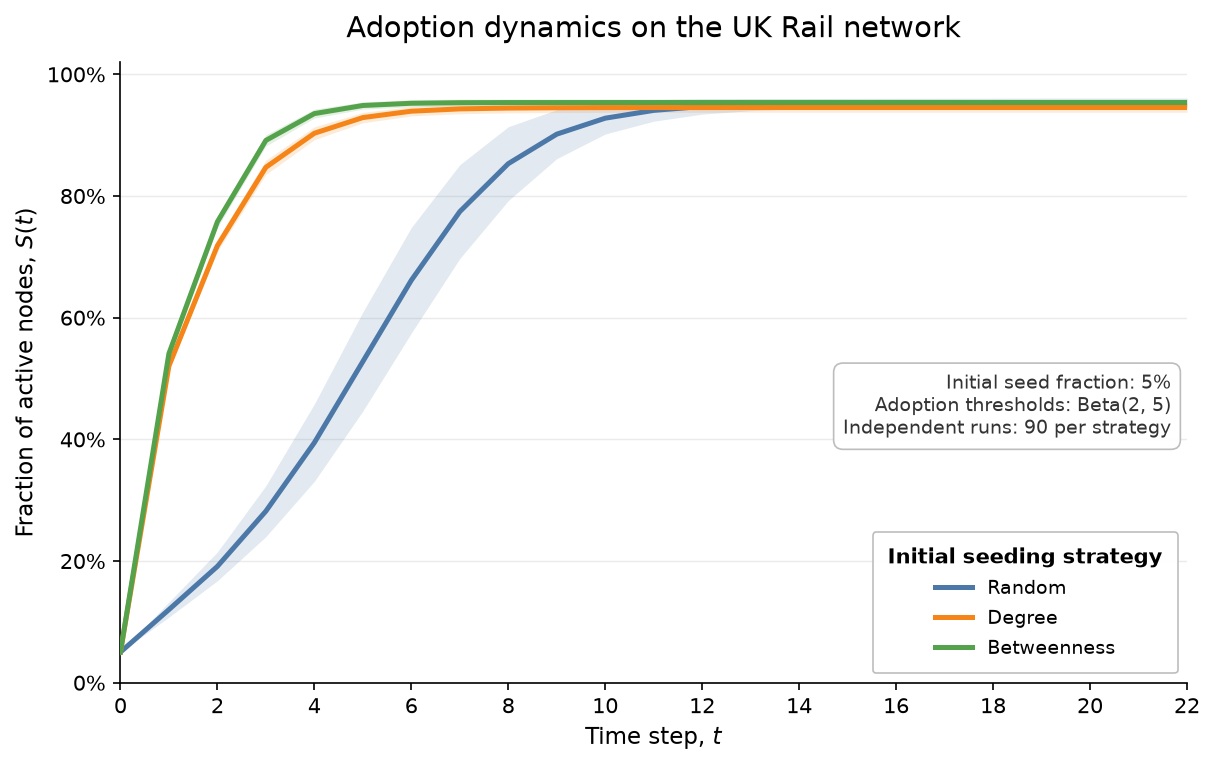

Saved figure to figures/adoption_trajectories_all_networks.png


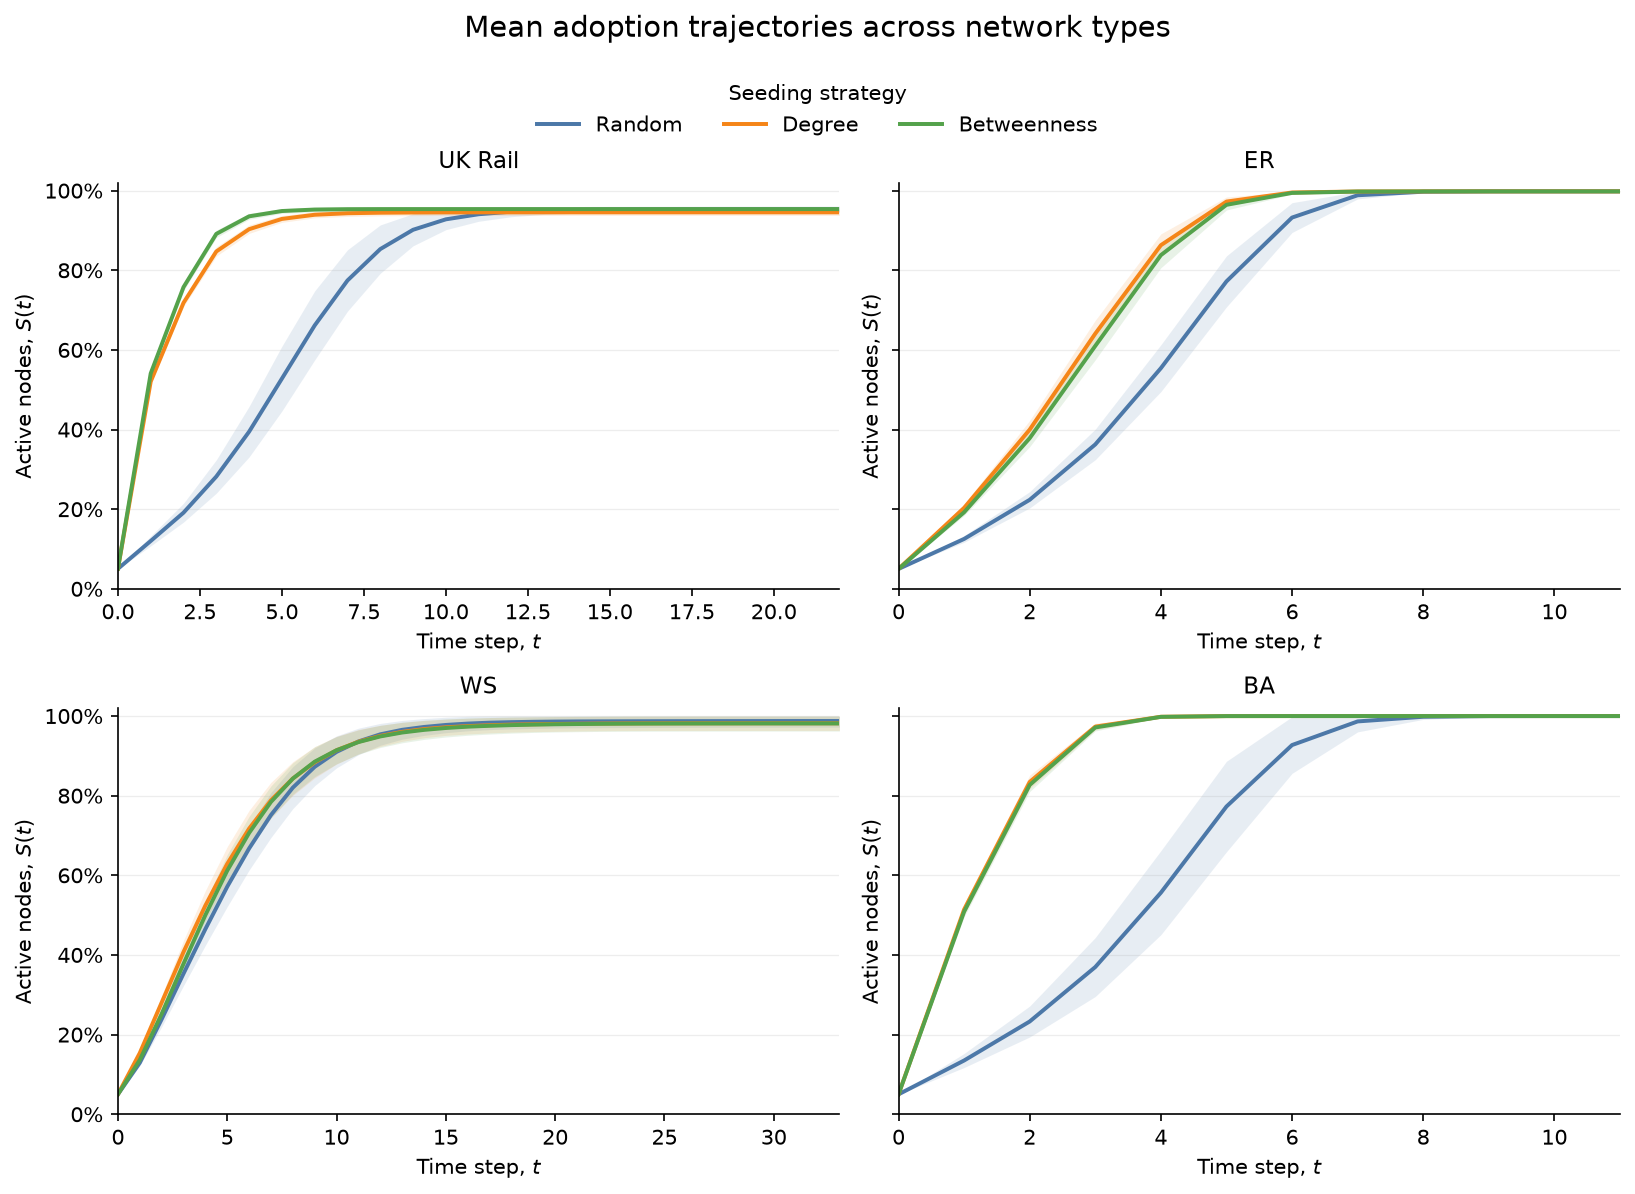

Saved figure to figures/uk_rail_strategy_boxplots.png


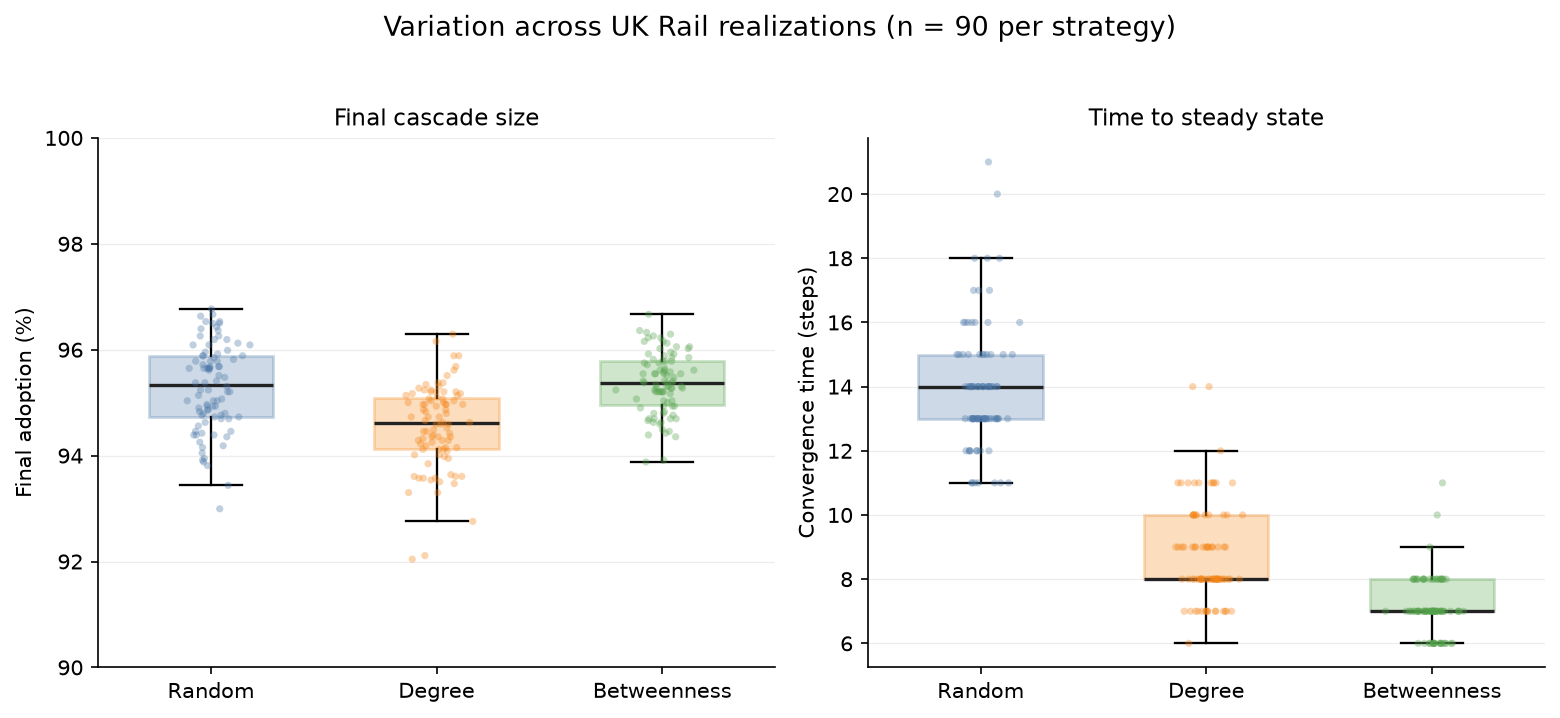

In [231]:
uk_rail_trials = df_results.loc[
    df_results["Network"].eq("UK Rail")
]
# Aggregate trial-level trajectories. Padding in the experiment runner holds each
# realization at its steady-state value, allowing trajectories to share a time axis.
trajectory_summary = (df_trajectories
    .groupby(["Network", "Strategy", "Time"])["AdoptionFraction"]
    .agg(mean="mean", std="std")
    .reset_index())
trajectory_summary["std"] = trajectory_summary["std"].fillna(0)

# ---- Figure 1: report-ready adoption trajectories for the empirical UK Rail network ----
rail_curve = trajectory_summary.loc[trajectory_summary["Network"].eq("UK Rail")]
rail_max_time = int(uk_rail_trials["ConvergenceTime"].max()) + 1

fig, ax = plt.subplots(figsize=(8.2, 5.2), dpi=150)
for strategy in strategy_order:
    part = rail_curve.loc[rail_curve["Strategy"].eq(strategy)].sort_values("Time")
    part = part.loc[part["Time"] <= rail_max_time]
    color = STRATEGY_COLORS[strategy]
    ax.plot(part["Time"], part["mean"], color=color, linewidth=2.4,
            label=strategy, zorder=3)
    lower = np.clip(part["mean"] - part["std"], 0, 1)
    upper = np.clip(part["mean"] + part["std"], 0, 1)
    ax.fill_between(part["Time"], lower, upper, color=color, alpha=0.16,
                    linewidth=0, zorder=2)

ax.set_title("Adoption dynamics on the UK Rail network", fontsize=14, pad=12)
ax.set_xlabel("Time step, $t$", fontsize=11)
ax.set_ylabel("Fraction of active nodes, $S(t)$", fontsize=11)
ax.set_xlim(0, rail_max_time)
ax.set_ylim(0, 1.02)
ax.set_xticks(range(0, rail_max_time + 1, 2))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.grid(axis="y", alpha=0.25, linewidth=0.7)
ax.spines[["top", "right"]].set_visible(False)
legend = ax.legend(
    title="Initial seeding strategy",
    loc="lower right",
    bbox_to_anchor=(1.0, 0.0),
    frameon=True,
    fancybox=True,
    framealpha=0.97,
    edgecolor="#BBBBBB",
    fontsize=9,
    title_fontsize=10,
    borderpad=0.8,
    labelspacing=0.6
)

legend.get_title().set_fontweight("bold")
legend.get_frame().set_linewidth(0.8)
ax.text(
    0.985, 0.50,
    "Initial seed fraction: 5%\n"
    "Adoption thresholds: Beta(2, 5)\n"
    "Independent runs: 90 per strategy",
    transform=ax.transAxes,
    fontsize=9,
    color="#333333",
    verticalalignment="top",
    horizontalalignment="right",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="#BBBBBB",
        linewidth=0.8,
        alpha=0.97
    ),
    zorder=10
)
fig.tight_layout()
save_figure_if_directory_exists(fig, "uk_rail_adoption_trajectories.png")
plt.show()

# ---- Figure 2: one panel per network for cross-topology context ----
network_order = ["UK Rail", "ER", "WS", "BA"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), dpi=150, sharey=True)
for ax, network_name in zip(axes.flat, network_order):
    part_network = trajectory_summary.loc[
        trajectory_summary["Network"].eq(network_name)]
    network_trials = df_results.loc[df_results["Network"].eq(network_name)]
    xmax = int(network_trials["ConvergenceTime"].max()) + 1
    for strategy in strategy_order:
        part = part_network.loc[part_network["Strategy"].eq(strategy)].sort_values("Time")
        part = part.loc[part["Time"] <= xmax]
        color = STRATEGY_COLORS[strategy]
        ax.plot(part["Time"], part["mean"], color=color, linewidth=1.9,
                label=strategy)
        ax.fill_between(part["Time"],
                        np.clip(part["mean"] - part["std"], 0, 1),
                        np.clip(part["mean"] + part["std"], 0, 1),
                        color=color, alpha=0.13, linewidth=0)
    ax.set_title(network_name, fontsize=11, pad=7)
    ax.set_xlim(0, xmax)
    ax.set_ylim(0, 1.02)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
    ax.grid(axis="y", alpha=0.22, linewidth=0.6)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_xlabel("Time step, $t$")
    ax.set_ylabel("Active nodes, $S(t)$")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Seeding strategy", loc="upper center",
           bbox_to_anchor=(0.5, 1.01), ncol=3, frameon=False)
fig.suptitle("Mean adoption trajectories across network types", y=1.055, fontsize=14)
fig.tight_layout()
save_figure_if_directory_exists(fig, "adoption_trajectories_all_networks.png")
plt.show()

# ---- Figure 3: trial-level distributions on UK Rail ----
# Boxplots summarize the 90 independent realizations per strategy. Jittered points
# show the underlying observations; the adoption axis is deliberately shown in %.
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.6), dpi=150)
metrics = [
    ("FinalAdoption", "Final adoption (%)", lambda x: 100 * x, (90, 100)),
    ("ConvergenceTime", "Convergence time (steps)", lambda x: x, None),
]
for ax, (metric, ylabel, transform, ylim) in zip(axes, metrics):
    data = [transform(uk_rail_trials.loc[
        uk_rail_trials["Strategy"].eq(strategy), metric].dropna().to_numpy())
        for strategy in strategy_order]
    bp = ax.boxplot(data, positions=np.arange(1, len(strategy_order) + 1),
                    widths=0.55, patch_artist=True, showfliers=False,
                    medianprops={"color": "#222222", "linewidth": 1.6},
                    whiskerprops={"linewidth": 1.1}, capprops={"linewidth": 1.1})
    for patch, strategy in zip(bp["boxes"], strategy_order):
        patch.set_facecolor(STRATEGY_COLORS[strategy])
        patch.set_alpha(0.28)
        patch.set_edgecolor(STRATEGY_COLORS[strategy])
        patch.set_linewidth(1.4)
    # Deterministic horizontal jitter to reveal the individual trial values.
    jitter_rng = np.random.default_rng(2026)
    for position, values, strategy in zip(range(1, 4), data, strategy_order):
        x_jitter = jitter_rng.normal(position, 0.055, size=len(values))
        ax.scatter(x_jitter, values, s=12, alpha=0.35,
                   color=STRATEGY_COLORS[strategy], edgecolors="none", zorder=3)
    ax.set_xticks(range(1, 4), strategy_order)
    ax.set_ylabel(ylabel)
    ax.grid(axis="y", alpha=0.22, linewidth=0.6)
    ax.spines[["top", "right"]].set_visible(False)
    if ylim is not None:
        ax.set_ylim(*ylim)

axes[0].set_title("Final cascade size", fontsize=11)
axes[1].set_title("Time to steady state", fontsize=11)
fig.suptitle("Variation across UK Rail realizations (n = 90 per strategy)",
             fontsize=13, y=1.03)
fig.tight_layout()
save_figure_if_directory_exists(fig, "uk_rail_strategy_boxplots.png")
plt.show()



## 12. Threshold Sensitivity

In [232]:
df_tau, trajectories_tau = run_sensitivity_sweep(
    G,
    parameter_name="tau",
    values=TAU_VALUES,
    runs=RUNS_PER_SETTING,
    seed_fraction=SEED_FRACTION,
    max_steps=MAX_STEPS,
    seed_base=RANDOM_SEED + 1_000_000,
)
save_dataframe_if_directory_exists(df_tau, "tau_sweep_trial_results.csv")

tau_summary = (
    df_tau.groupby(["Parameter", "Strategy"])["FinalAdoption"]
    .agg(["mean", "std", "count"])
    .reset_index()
)
display(tau_summary)

# Report the first tested threshold at which mean final adoption falls below 50%.
for strategy in STRATEGIES:
    strategy_results = (
        tau_summary[tau_summary["Strategy"].eq(strategy)]
        .sort_values("Parameter")
    )
    below_criterion = strategy_results[strategy_results["mean"] < 0.5]
    tipping_value = (
        float(below_criterion["Parameter"].iloc[0])
        if not below_criterion.empty else np.nan
    )
    print(f"{strategy}: first tested threshold with mean S∞ < 0.5 = {tipping_value}")


Saved data to data/tau_sweep_trial_results.csv


,Parameter,Strategy,mean,std,count
0,0.05,Betweenness,0.974838,0.000000,30
1,0.05,Degree,0.974838,0.000000,30
2,0.05,Random,0.977899,0.001426,30
3,0.10,Betweenness,0.974838,0.000000,30
4,0.10,Degree,0.974838,0.000000,30
5,0.10,Random,0.978035,0.001428,30
6,0.15,Betweenness,0.972118,0.000000,30
7,0.15,Degree,0.972118,0.000000,30
8,0.15,Random,0.975995,0.001870,30
9,0.20,Betweenness,0.974838,0.000000,30


Random: first tested threshold with mean S∞ < 0.5 = 0.35
Degree: first tested threshold with mean S∞ < 0.5 = nan
Betweenness: first tested threshold with mean S∞ < 0.5 = nan


Saved figure to figures/uk_rail_threshold_sensitivity.png


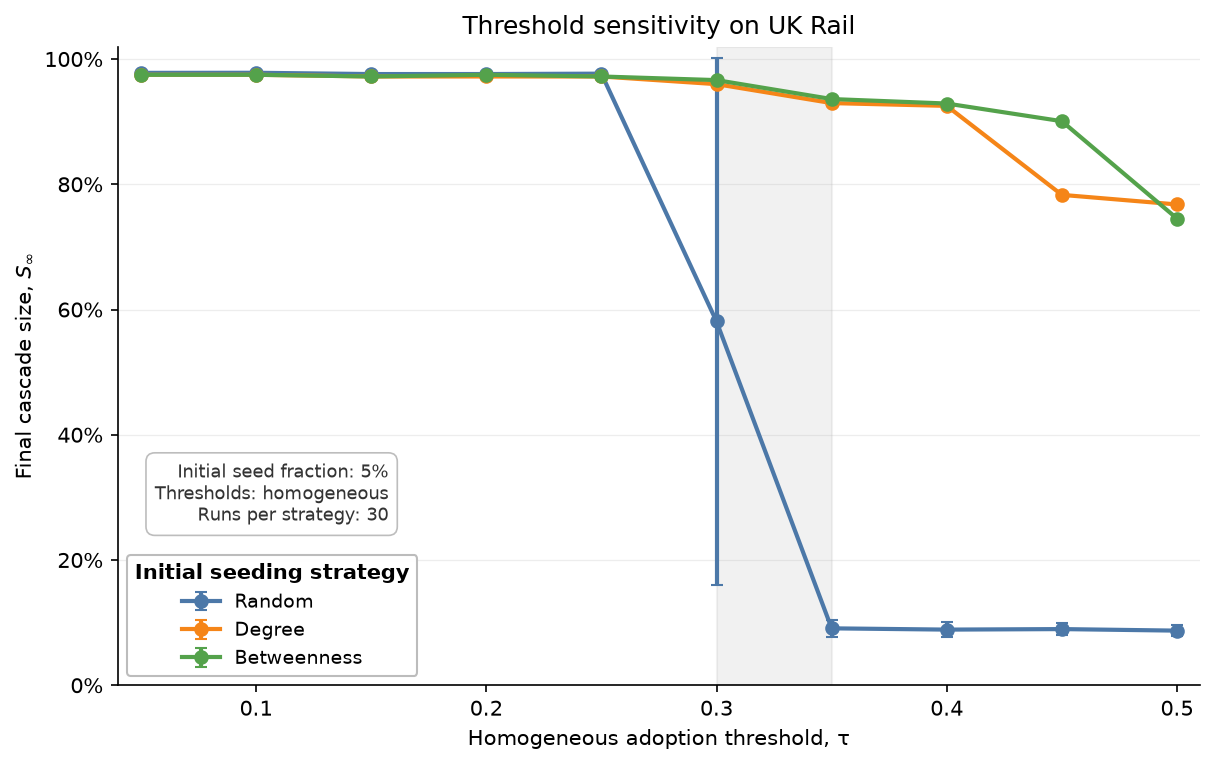

In [233]:
fig, ax = plt.subplots(figsize=(8.2, 5.2), dpi=150)

for strategy in strategy_order:
    part = tau_summary.loc[
        tau_summary["Strategy"].eq(strategy)
    ].sort_values("Parameter")

    ax.errorbar(
        part["Parameter"],
        part["mean"],
        yerr=part["std"].fillna(0),
        color=STRATEGY_COLORS[strategy],
        marker="o",
        markersize=6,
        linewidth=2,
        capsize=3,
        label=strategy,
        zorder=3
    )

# Highlight the observed tipping interval for random seeding
ax.axvspan(0.30, 0.35, color="#999999", alpha=0.13, zorder=0)

ax.set(
    title="Threshold sensitivity on UK Rail",
    xlabel="Homogeneous adoption threshold, τ",
    ylabel="Final cascade size, $S_\\infty$"
)

ax.set_ylim(0, 1.02)
ax.set_xlim(0.04, 0.51)
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.0%}")
)

# Minimal grid
ax.grid(axis="y", alpha=0.22, linewidth=0.6)
ax.spines[["top", "right"]].set_visible(False)

# Legend
legend = ax.legend(
    title="Initial seeding strategy",
    loc="lower left",
    frameon=True,
    fancybox=True,
    framealpha=0.98,
    edgecolor="#BBBBBB",
    fontsize=9,
    title_fontsize=10
)
legend.get_title().set_fontweight("bold")

# Information box directly above legend
ax.text(
    0.25, 0.35,
    "Initial seed fraction: 5%\n"
    "Thresholds: homogeneous\n"
    "Runs per strategy: 30",
    transform=ax.transAxes,
    fontsize=8.5,
    color="#333333",
    va="top",
    ha="right",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="#BBBBBB",
        linewidth=0.8,
        alpha=0.97
    ),
    zorder=5
)

fig.tight_layout()
save_figure_if_directory_exists(fig, "uk_rail_threshold_sensitivity.png")
plt.show()

## 12(B). Fine-grained threshold sweep

In [234]:
# Run a finer threshold sweep around the transition observed in the coarse sweep.
FINE_TAU_VALUES = np.round(np.arange(0.30, 0.3501, 0.002), 3)
FINE_RUNS = 50

df_tau_fine, trajectories_tau_fine = run_sensitivity_sweep(
    G,
    parameter_name="tau",
    values=FINE_TAU_VALUES,
    runs=FINE_RUNS,
    seed_fraction=SEED_FRACTION,
    max_steps=MAX_STEPS,
    seed_base=RANDOM_SEED + 3_000_000,
)

save_dataframe_if_directory_exists(df_tau_fine, "tau_sweep_fine_trial_results.csv")

# Summarise final adoption and cascade success
tau_fine_summary = (
    df_tau_fine.groupby(["Parameter", "Strategy"])
    .agg(
        mean_adoption=("FinalAdoption", "mean"),
        std_adoption=("FinalAdoption", "std"),
        cascade_probability=("CascadeSuccess", "mean"),
        n=("FinalAdoption", "count")
    )
    .reset_index()
)

display(tau_fine_summary)

Saved data to data/tau_sweep_fine_trial_results.csv


,Parameter,Strategy,mean_adoption,std_adoption,cascade_probability,n
0,0.300,Betweenness,0.966338,0.00000,1.00,50
1,0.300,Degree,0.959878,0.00000,1.00,50
2,0.300,Random,0.542951,0.41300,0.48,50
3,0.302,Betweenness,0.966338,0.00000,1.00,50
4,0.302,Degree,0.959878,0.00000,1.00,50
...,...,...,...,...,...,...
73,0.348,Degree,0.929616,0.00000,1.00,50
74,0.348,Random,0.095587,0.01574,0.00,50
75,0.350,Betweenness,0.930636,0.00000,1.00,50
76,0.350,Degree,0.929616,0.00000,1.00,50


In [235]:
# Identify the first threshold where mean final adoption falls below 50%
for strategy in strategy_order:
    part = (
        tau_fine_summary[
            tau_fine_summary["Strategy"] == strategy
        ]
        .sort_values("Parameter")
    )

    below = part[part["mean_adoption"] < 0.5]

    if not below.empty:
        tipping_tau = below.iloc[0]["Parameter"]
        print(f"{strategy}: first tested tipping threshold = {tipping_tau:.3f}")
    else:
        print(f"{strategy}: no tipping point found in tested interval")

print("\nDetailed random-seeding results:")
display(
    tau_fine_summary[
        tau_fine_summary["Strategy"] == "Random"
    ][["Parameter", "mean_adoption", "std_adoption", "cascade_probability"]]
)

Random: first tested tipping threshold = 0.302
Degree: no tipping point found in tested interval
Betweenness: no tipping point found in tested interval

Detailed random-seeding results:


,Parameter,mean_adoption,std_adoption,cascade_probability
2,0.300,0.542951,0.413000,0.48
5,0.302,0.484243,0.400373,0.40
8,0.304,0.524597,0.413273,0.46
11,0.306,0.398048,0.380034,0.30
14,0.308,0.377239,0.359783,0.26
17,0.310,0.370588,0.362327,0.26
20,0.312,0.274621,0.306067,0.16
23,0.314,0.320775,0.329359,0.20
26,0.316,0.217463,0.229260,0.08
29,0.318,0.245406,0.249357,0.10


Saved figure to figures/uk_rail_threshold_fine_sensitivity.png


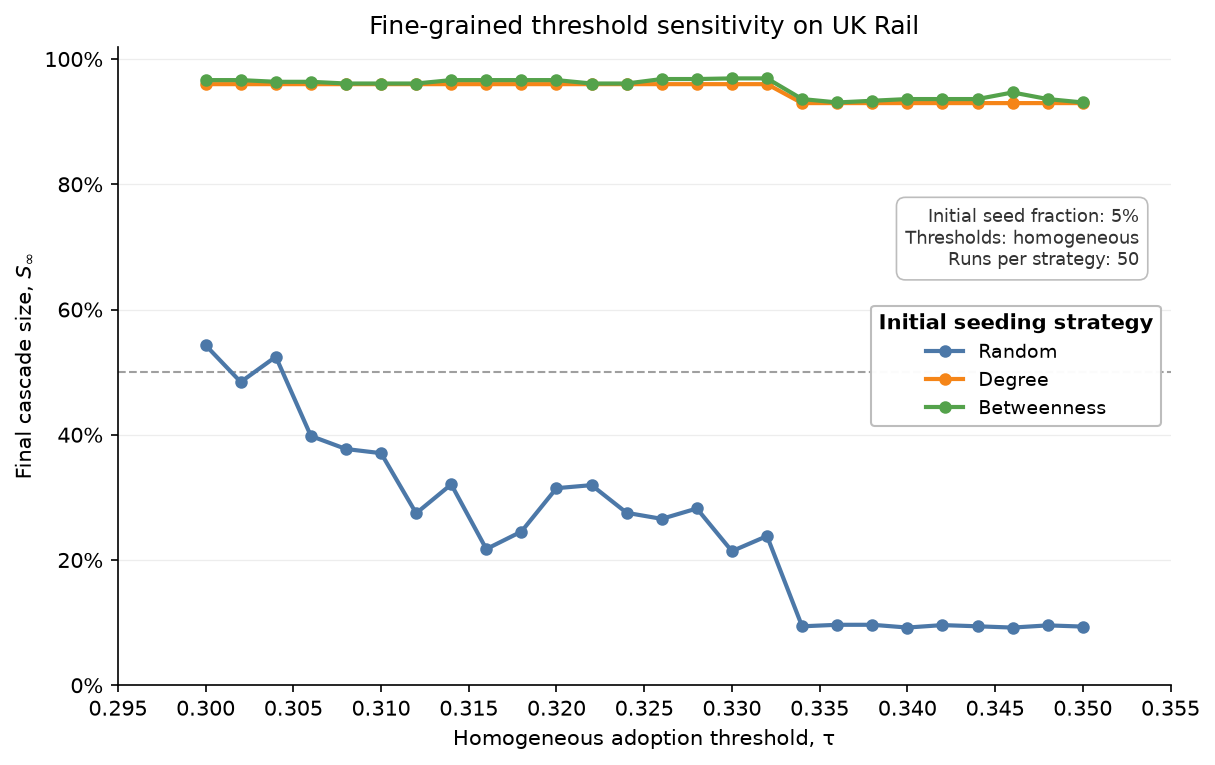

In [236]:
fig, ax = plt.subplots(figsize=(8.2, 5.2), dpi=150)

for strategy in strategy_order:
    part = (
        tau_fine_summary[
            tau_fine_summary["Strategy"] == strategy
        ].sort_values("Parameter")
    )

    ax.plot(
        part["Parameter"],
        part["mean_adoption"],
        color=STRATEGY_COLORS[strategy],
        marker="o",
        markersize=5,
        linewidth=2,
        label=strategy,
        zorder=3
    )

# Reference line for the 50% cascade criterion
ax.axhline(
    0.5,
    color="#777777",
    linestyle="--",
    linewidth=1,
    alpha=0.7,
    zorder=1
)

ax.set(
    title="Fine-grained threshold sensitivity on UK Rail",
    xlabel="Homogeneous adoption threshold, τ",
    ylabel="Final cascade size, $S_\\infty$"
)

ax.set_xlim(0.295, 0.355)
ax.set_ylim(0, 1.02)

ax.xaxis.set_major_locator(plt.MultipleLocator(0.005))
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.0%}")
)

ax.grid(axis="y", alpha=0.22, linewidth=0.6)
ax.spines[["top", "right"]].set_visible(False)

# Legend
legend = ax.legend(
    title="Initial seeding strategy",
    loc="right",
    frameon=True,
    fancybox=True,
    framealpha=0.97,
    edgecolor="#BBBBBB",
    fontsize=9,
    title_fontsize=10
)
legend.get_title().set_fontweight("bold")

# Information box
ax.text(
    0.97, 0.75,
    "Initial seed fraction: 5%\n"
    "Thresholds: homogeneous\n"
    "Runs per strategy: 50",
    transform=ax.transAxes,
    fontsize=8.5,
    color="#333333",
    va="top",
    ha="right",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="#BBBBBB",
        linewidth=0.8,
        alpha=0.97
    ),
    zorder=5
)

fig.tight_layout()
save_figure_if_directory_exists(fig, "uk_rail_threshold_fine_sensitivity.png")
plt.show()

## 13. Seed-fraction Sensitivity

In [237]:
df_f0, trajectories_f0 = run_sensitivity_sweep(
    G,
    parameter_name="f0",
    values=F0_VALUES,
    runs=RUNS_PER_SETTING,
    fixed_tau=INTERMEDIATE_TAU,
    max_steps=MAX_STEPS,
    seed_base=RANDOM_SEED + 2_000_000,
)
save_dataframe_if_directory_exists(df_f0, "seed_fraction_sweep_trial_results.csv")

f0_summary = (
    df_f0.groupby(["Parameter", "Strategy"])["FinalAdoption"]
    .agg(["mean", "std", "count"])
    .reset_index()
)
display(f0_summary)


Saved data to data/seed_fraction_sweep_trial_results.csv


,Parameter,Strategy,mean,std,count
0,0.01,Betweenness,0.972118,0.000000,30
1,0.01,Degree,0.972118,0.000000,30
2,0.01,Random,0.941403,0.172218,30
3,0.02,Betweenness,0.972118,0.000000,30
4,0.02,Degree,0.972118,0.000000,30
5,0.02,Random,0.973218,0.001118,30
6,0.05,Betweenness,0.972118,0.000000,30
7,0.05,Degree,0.972118,0.000000,30
8,0.05,Random,0.976199,0.001675,30
9,0.10,Betweenness,0.974838,0.000000,30


Saved figure to figures/uk_rail_seed_fraction_sensitivity.png


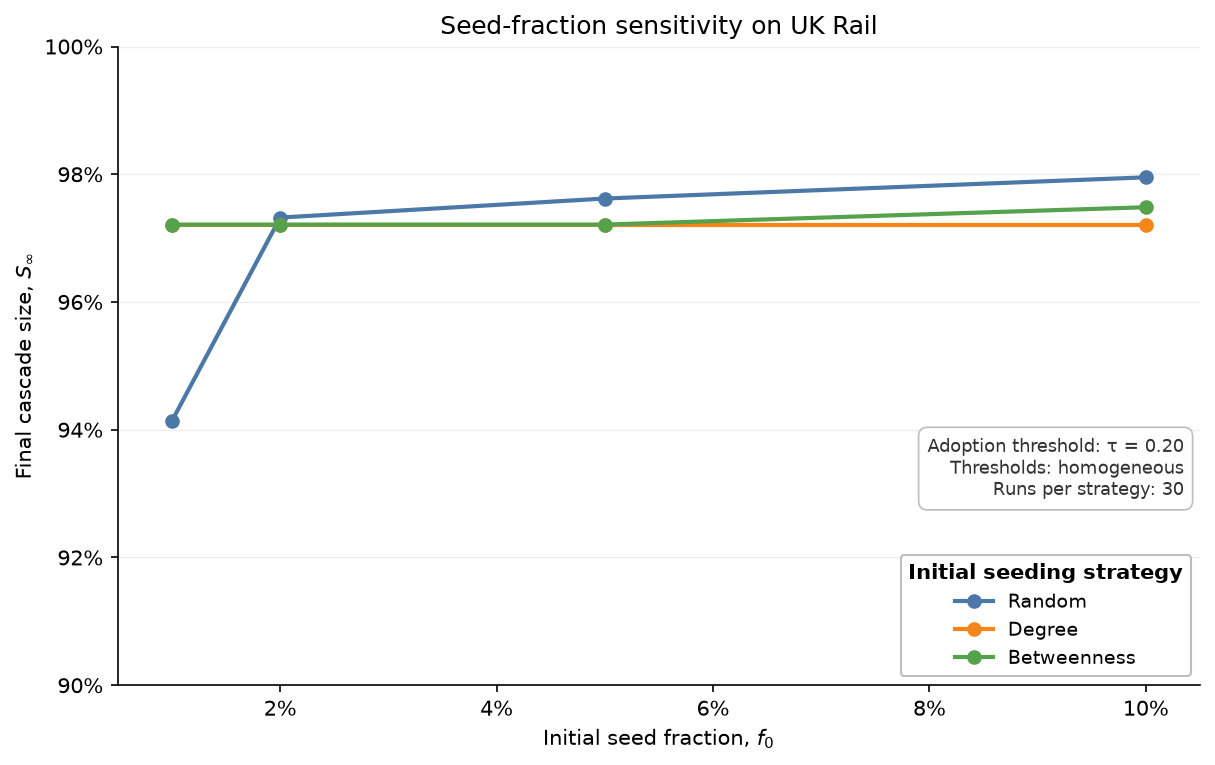

In [238]:
fig, ax = plt.subplots(figsize=(8.2, 5.2), dpi=150)

for strategy in strategy_order:
    part = f0_summary.loc[
        f0_summary["Strategy"].eq(strategy)
    ].sort_values("Parameter")

    ax.plot(
        part["Parameter"],
        part["mean"],
        color=STRATEGY_COLORS[strategy],
        marker="o",
        markersize=6,
        linewidth=2,
        label=strategy,
        zorder=3
    )

ax.set(
    title="Seed-fraction sensitivity on UK Rail",
    xlabel="Initial seed fraction, $f_0$",
    ylabel="Final cascade size, $S_\\infty$"
)

# Zoom into the relevant range
ax.set_ylim(0.90, 1.00)
ax.set_xlim(0.005, 0.105)

ax.xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:.0%}")
)
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda y, _: f"{y:.0%}")
)

ax.grid(axis="y", alpha=0.22, linewidth=0.6)
ax.spines[["top", "right"]].set_visible(False)

# Legend
legend = ax.legend(
    title="Initial seeding strategy",
    loc="lower right",
    frameon=True,
    fancybox=True,
    framealpha=0.97,
    edgecolor="#BBBBBB",
    fontsize=9,
    title_fontsize=10
)
legend.get_title().set_fontweight("bold")

# Information box directly above legend
ax.text(
    0.985, 0.39,
    "Adoption threshold: τ = 0.20\n"
    "Thresholds: homogeneous\n"
    "Runs per strategy: 30",
    transform=ax.transAxes,
    fontsize=8.5,
    color="#333333",
    va="top",
    ha="right",
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="#BBBBBB",
        linewidth=0.8,
        alpha=0.97
    ),
    zorder=5
)

fig.tight_layout()
save_figure_if_directory_exists(fig, "uk_rail_seed_fraction_sensitivity.png")
plt.show()